In [9]:
from datetime import date

today = date.today()
print(f'Last full compilation {today}')

Last full compilation 2023-06-01


# Cas de référence : échantillon monolithique

Noms des campagnes : 
- `campagne_honey`
- `campagne_honey_CC`
- `campagne_honey_UR3_S13`
- `campagne_honey_UR3_S7`

## Mapping sans CC en fct de theta et la taille du motif

In [10]:
from classes import *
from funcData import *
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
from math import *
from math_func import *

import matplotlib as mpl
mpl.rcParams['figure.dpi'] = 100


campagnes = ['campagne_honey','campagne_carre','campagne_trian', 'campagne_hexac']
# Can be long the first time
data=read_data_from_database(campagnes)
data_bulk = get_bulk_data(data)

Lecture des données réalisée en 1.65629s


[10.503091071287221, 52.60742576457445, 144.70313919173708, 127.62856671443045]


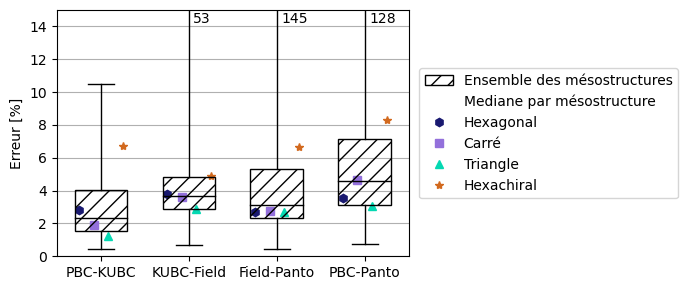

In [11]:
err = [[] for i in range(4)]
colors=['midnightblue', 'mediumpurple', '#04D8B2', 'chocolate']

for _, test in data_bulk.items():
    err[0].append(test.get_error((0, 1)))
    err[1].append(test.get_error((1, 2)))
    err[2].append(test.get_error((2, 3)))
    err[3].append(test.get_error((0, 3)))
print([max(i) for i in err])

mean_err_per_geo = np.zeros((4, 4, max([len(c) for _, c in data.items()])))
mean_err_per_geo[:] = np.nan
counter = [0, 0, 0, 0]

for c_name, campagne in data.items():
    geo_idx = campagnes.index(c_name)
    for _, test in campagne.items():
        mean_err_per_geo[0, geo_idx, counter[geo_idx]] = test.get_error((0, 1))
        mean_err_per_geo[1, geo_idx, counter[geo_idx]] = test.get_error((1, 2))
        mean_err_per_geo[2, geo_idx, counter[geo_idx]] = test.get_error((2, 3))
        mean_err_per_geo[3, geo_idx, counter[geo_idx]] = test.get_error((0, 3))
        counter[geo_idx] += 1

mean_err_per_geo = np.nanquantile(mean_err_per_geo,0.5, axis=2).tolist()

plt.figure(figsize=(7, 3))
bp=plt.boxplot(err, patch_artist=True, whis=(0, 100), medianprops={
            'color': 'k'}, boxprops={'fill': False, 'hatch':'//'},widths=0.6)

# * Legende
nn = mlines.Line2D([], [], color='w', marker='*', linestyle='')
hexa = mlines.Line2D([], [], color=colors[0], marker='h', linestyle='')
carre = mlines.Line2D([], [], color=colors[1], marker='s', linestyle='')
trian = mlines.Line2D([], [], color=colors[2], marker='^', linestyle='')
hc = mlines.Line2D([], [], color=colors[3], marker='*', linestyle='')
plt.legend([bp['boxes'][0],nn, hexa,carre,trian,hc],['Ensemble des mésostructures','Mediane par mésostructure','Hexagonal','Carré', 'Triangle', 'Hexachiral'],
           fancybox=True,loc='center left', bbox_to_anchor=(1.01, 0.5))


plt.ylim(top=15, bottom=0)
plt.ylabel('Erreur [%]')
plt.xticks(range(1, 5), ['PBC-KUBC',
                         'KUBC-Field',
                         'Field-Panto',
                         'PBC-Panto'])

plt.text(2.05,14.9,f'{max(err[1][:]):.0f}', va='top', ha='left')
plt.text(3.05,14.9,f'{max(err[2][:]):.0f}', va='top', ha='left')
plt.text(4.05,14.9,f'{max(err[3][:]):.0f}', va='top', ha='left')


markers = ['h', 's', '^', '*']
n=6 # Space between indivuals medians

for i_error, error in enumerate(mean_err_per_geo):
    for i_geo, geo in enumerate(error):
        plt.plot([i_error+1-(1/n+1/n/2)+1/n*i_geo], [geo], markers[i_geo], color=colors[i_geo])
plt.grid(axis='y')

plt.tight_layout()
plt.savefig('images/mapping_error_glob.pdf')


[3.752313755096368e-10, 1.2460116968803605e-05, 25.816315566721087, 55.421979668123186]


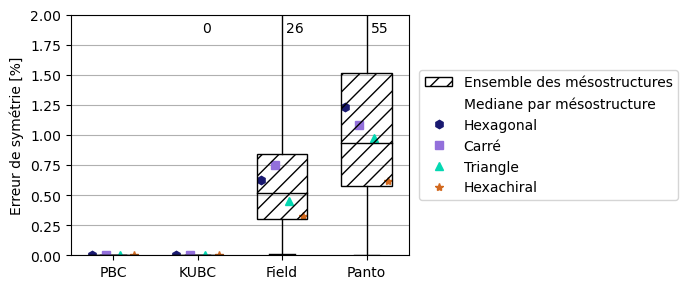

In [12]:

#~ Erreur de symétrie
err = [[] for i in range(4)]
colors=['midnightblue', 'mediumpurple', '#04D8B2', 'chocolate']

for _, test in data_bulk.items():
    err[0].append(get_sym_error(test.K_plane_stress_PBC))
    err[1].append(get_sym_error(test.K_plane_stress_KUBC))
    err[2].append(get_sym_error(test.K_field_dic))
    err[3].append(get_sym_error(test.K_panto_dic))
print([max(i) for i in err])

mean_err_per_geo = np.zeros((4, 4, max([len(c) for _, c in data.items()])))
mean_err_per_geo[:] = np.nan
counter = [0, 0, 0, 0]

for c_name, campagne in data.items():
    geo_idx = campagnes.index(c_name)
    for _, test in campagne.items():
        mean_err_per_geo[0, geo_idx, counter[geo_idx]] = get_sym_error(test.K_plane_stress_PBC)
        mean_err_per_geo[1, geo_idx, counter[geo_idx]] = get_sym_error(test.K_plane_stress_KUBC)
        mean_err_per_geo[2, geo_idx, counter[geo_idx]] = get_sym_error(test.K_field_dic)
        mean_err_per_geo[3, geo_idx, counter[geo_idx]] = get_sym_error(test.K_panto_dic)
        counter[geo_idx] += 1

mean_err_per_geo = np.nanquantile(mean_err_per_geo,0.5, axis=2).tolist()

plt.figure(figsize=(7, 3))
bp=plt.boxplot(err, patch_artist=True, whis=(0, 100), medianprops={
            'color': 'k'}, boxprops={'fill': False, 'hatch':'//'},widths=0.6)

# * Legende
nn = mlines.Line2D([], [], color='w', marker='*', linestyle='')
hexa = mlines.Line2D([], [], color=colors[0], marker='h', linestyle='')
carre = mlines.Line2D([], [], color=colors[1], marker='s', linestyle='')
trian = mlines.Line2D([], [], color=colors[2], marker='^', linestyle='')
hc = mlines.Line2D([], [], color=colors[3], marker='*', linestyle='')
plt.legend([bp['boxes'][0],nn, hexa,carre,trian,hc],['Ensemble des mésostructures','Mediane par mésostructure','Hexagonal','Carré', 'Triangle', 'Hexachiral'],
           fancybox=True,loc='center left', bbox_to_anchor=(1.01, 0.5))


plt.ylim(top=2, bottom=0)
plt.ylabel('Erreur de symétrie [%]')
plt.xticks(range(1, 5), ['PBC',
                         'KUBC',
                         'Field',
                         'Panto'])

plt.text(2.05,1.95,f'{max(err[1][:]):.0f}', va='top', ha='left')
plt.text(3.05,1.95,f'{max(err[2][:]):.0f}', va='top', ha='left')
plt.text(4.05,1.95,f'{max(err[3][:]):.0f}', va='top', ha='left')


markers = ['h', 's', '^', '*']
n=6 # Space between indivuals medians

for i_error, error in enumerate(mean_err_per_geo):
    for i_geo, geo in enumerate(error):
        plt.plot([i_error+1-(1/n+1/n/2)+1/n*i_geo], [geo], markers[i_geo], color=colors[i_geo])
plt.grid(axis='y')

plt.tight_layout()
plt.savefig('images/mapping_error_sym.pdf')


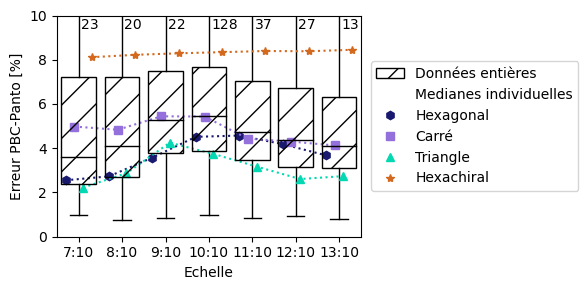

In [13]:

err = [[] for i in range(7)]

for test_id, test in data_bulk.items():
    err[int(test_id.split('_')[1])-7].append(test.get_error((0, 3)))

mean_err_per_geo = np.zeros((7, 4, max([len(c) for _, c in data.items()])))
mean_err_per_geo[:] = np.nan
counter = np.zeros((7,4))

for c_name, campagne in data.items():
    geo_idx = campagnes.index(c_name)
    for test_id, test in campagne.items():
        scale=int(test_id.split('_')[1])-7
        mean_err_per_geo[scale, geo_idx, int(counter[scale,geo_idx])] = test.get_error((0, 3))
        counter[scale,geo_idx] += 1

mean_err_per_geo = np.nanquantile(mean_err_per_geo,0.5, axis=2).tolist()

plt.figure(figsize=(6, 3))
bp=plt.boxplot(err, patch_artist=True, whis=(0, 100), medianprops={
            'color': 'k'}, boxprops={'fill': False, 'hatch':'/'},widths=0.8)

# * Legende
nn = mlines.Line2D([], [], color='w', marker='*', linestyle='')
hexa = mlines.Line2D([], [], color=colors[0], marker='h', linestyle='')
carre = mlines.Line2D([], [], color=colors[1], marker='s', linestyle='')
trian = mlines.Line2D([], [], color=colors[2], marker='^', linestyle='')
hc = mlines.Line2D([], [], color=colors[3], marker='*', linestyle='')
plt.legend([bp['boxes'][0],nn, hexa,carre,trian,hc],['Données entières','Medianes individuelles','Hexagonal','Carré', 'Triangle', 'Hexachiral'],
           fancybox=True,loc='center left', bbox_to_anchor=(1.01, 0.5))


ymax=10

markers = ['h:', 's:', '^:', '*:']
n=5 # Space between indivuals medians

for i_geo in range(4):
    plt.plot([i_error+1-(1/n+1/n/2)+1/n*i_geo for i_error in range(7)], [e[i_geo] for e in mean_err_per_geo], markers[i_geo], color=colors[i_geo])

for i in range(7):
    plt.text(i+1.05,ymax-0.1,f'{max(err[i][:]):.0f}', va='top', ha='left')


plt.ylim(bottom=0.0,top=ymax)

plt.xlabel('Echelle')
plt.ylabel('Erreur PBC-Panto [%]')
plt.xticks(range(1, 8), ['7:10','8:10','9:10','10:10','11:10','12:10','13:10'])

plt.tight_layout()
plt.savefig('images/error_per_scale.pdf')

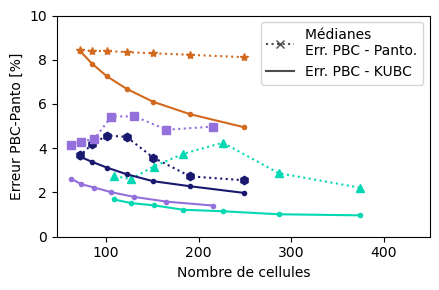

In [14]:

mean_err_per_geo_th = np.zeros((7, 4, max([len(c) for _, c in data.items()])))
mean_err_per_geo_th[:] = np.nan
counter = np.zeros((7,4))

for c_name, campagne in data.items():
    geo_idx = campagnes.index(c_name)
    for test_id, test in campagne.items():
        scale=int(test_id.split('_')[1])-7
        mean_err_per_geo_th[scale, geo_idx, int(counter[scale,geo_idx])] = test.get_error((0, 1))
        counter[scale,geo_idx] += 1

mean_err_per_geo_th = np.nanquantile(mean_err_per_geo_th,0.5, axis=2).tolist()
nb_cell=[]
L0=28

for scale in range(7,14):
    L=L0*scale/10
    nb_cell.append([288**2/(L/2*L*tan(pi/6)+L*L*tan(pi/6)),         # Hexa
                         288**2/(L**2),                             # Carre
                         288**2/(L*L*tan(pi/6))])                   # Triangle


markers = ['h:', 's:', '^:', '*:']
plt.figure(figsize=(4.5,3))
n=5 # Space between indivuals medians
for i_geo in range(4):
    plt.plot([nb_cell[i_error][i_geo%3] for i_error in range(7)], [e[i_geo] for e in mean_err_per_geo], markers[i_geo], color=colors[i_geo])

markers = ['.-']*4
for i_geo in range(4):
    plt.plot([nb_cell[i_error][i_geo%3] for i_error in range(7)], [e[i_geo] for e in mean_err_per_geo_th], markers[i_geo], color=colors[i_geo])


# * Legende
l0 =  mlines.Line2D([], [], color='0.3', marker='x', linestyle=':')
l1 = mlines.Line2D([], [], color='0.3', marker='', linestyle='-')
plt.legend([l0,l1,],['Médianes \nErr. PBC - Panto.','Err. PBC - KUBC'],
           fancybox=True)


plt.xlabel('Nombre de cellules')
plt.ylabel('Erreur PBC-Panto [%]')
plt.ylim((0,10))
plt.xlim(right=450)
plt.tight_layout()
plt.savefig('images/error_per_nb_cells.pdf')
plt.show()



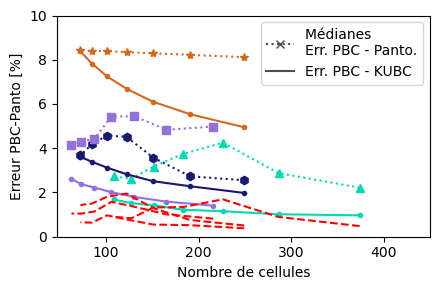

In [15]:

mean_err_per_geo_bis = np.zeros((7, 4, max([len(c) for _, c in data.items()])))
mean_err_per_geo_bis[:] = np.nan
counter = np.zeros((7,4))

for c_name, campagne in data.items():
    geo_idx = campagnes.index(c_name)
    for test_id, test in campagne.items():
        scale=int(test_id.split('_')[1])-7
        mean_err_per_geo_bis[scale, geo_idx, int(counter[scale,geo_idx])] = get_error_custom(test.K_panto_dic)
        counter[scale,geo_idx] += 1

mean_err_per_geo_bis = np.nanquantile(mean_err_per_geo_bis,0.5, axis=2).tolist()
nb_cell=[]
L0=28

for scale in range(7,14):
    L=L0*scale/10
    nb_cell.append([288**2/(L/2*L*tan(pi/6)+L*L*tan(pi/6)),         # Hexa
                         288**2/(L**2),                             # Carre
                         288**2/(L*L*tan(pi/6))])                   # Triangle


markers = ['h:', 's:', '^:', '*:']
plt.figure(figsize=(4.5,3))
n=5 # Space between indivuals medians
for i_geo in range(4):
    plt.plot([nb_cell[i_error][i_geo%3] for i_error in range(7)], [e[i_geo] for e in mean_err_per_geo], markers[i_geo], color=colors[i_geo])

markers = ['.-']*4
for i_geo in range(4):
    plt.plot([nb_cell[i_error][i_geo%3] for i_error in range(7)], [e[i_geo] for e in mean_err_per_geo_th], markers[i_geo], color=colors[i_geo])

markers = ['--']*4
for i_geo in range(4):
    plt.plot([nb_cell[i_error][i_geo%3] for i_error in range(7)], [e[i_geo] for e in mean_err_per_geo_bis], markers[i_geo], color='red')


# * Legende
l0 =  mlines.Line2D([], [], color='0.3', marker='x', linestyle=':')
l1 = mlines.Line2D([], [], color='0.3', marker='', linestyle='-')
plt.legend([l0,l1,],['Médianes \nErr. PBC - Panto.','Err. PBC - KUBC'],
           fancybox=True)


plt.xlabel('Nombre de cellules')
plt.ylabel('Erreur PBC-Panto [%]')
plt.ylim((0,10))
plt.xlim(right=450)
plt.tight_layout()
plt.savefig('images/error_per_nb_cells.pdf')
plt.show()


Lecture des données réalisée en 0.11793s
0
1
2
3


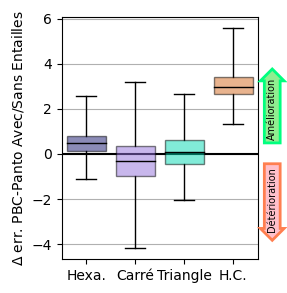

In [16]:

campagnes_CC = ['campagne_honey_CC','campagne_carre_CC','campagne_trian_CC', 'campagne_hexac_CC']
# Can be long the first time
data_CC=read_data_from_database(campagnes_CC)
data_CC_bulk = get_bulk_data(data_CC)


amelioration=[[] for i in range(4)]
eoi=(0,3)

for c_name, campagne in data_CC.items():
    geo_idx = campagnes_CC.index(c_name)
    print(geo_idx)
    for test_id, test in campagne.items():
        try:
            ref=data_bulk[test_id.replace('CC','')]
        except:
            print(f'{test_id} non trouvé')
            continue
        amelioration[geo_idx].append(-(test.get_error(eoi)-ref.get_error(eoi)))


plt.figure(figsize=(3, 3))
plt.axhline(0, color='black')
for i_geo in range(4):
    plt.boxplot([amelioration[i_geo]], patch_artist=True, whis=(0, 100), medianprops={
                'color': 'k'},boxprops={'facecolor':colors[i_geo],'alpha':0.5},widths=0.8,positions=[i_geo+1])

# plt.boxplot(amelioration, patch_artist=True, whis=(0, 100), medianprops={
#                 'color': 'k'},widths=0.8)

plt.text(4.8, 2, "Amélioration",
            ha="center", va="center", rotation=90, size=7,
            bbox=dict(boxstyle="rarrow,pad=0.3",
                      fc="lightgreen", ec="springgreen", lw=2))

plt.text(4.8, -2, "Détérioration",
            ha="center", va="center", rotation=90, size=7,
            bbox=dict(boxstyle="larrow,pad=0.3",
                      fc="pink", ec="coral", lw=2))
plt.grid(axis='y')

plt.xticks(range(1,5),['Hexa.', 'Carré', 'Triangle', 'H.C.'])
plt.ylabel(r'$\Delta$ err. PBC-Panto Avec/Sans Entailles')


plt.tight_layout()

Lecture des données réalisée en 0.49367s


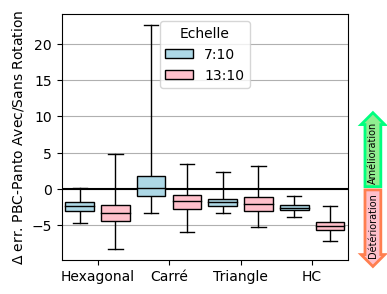

In [17]:

campagnes_R3 = ['campagne_honey_UR3_S7','campagne_honey_UR3_S13',
                'campagne_carre_UR3_S7','campagne_carre_UR3_S13',
                'campagne_trian_UR3_S7','campagne_trian_UR3_S13', 
                'campagne_hexac_UR3_S7','campagne_hexac_UR3_S13']
# Can be long the first time
data_R3=read_data_from_database(campagnes_R3)



amelioration=[[] for i in range(8)]
eoi=(0,3)

for c_name, campagne in data_R3.items():
    geo_idx = campagnes_R3.index(c_name)
    for test_id, test in campagne.items():
        try:
            ref=data_bulk[test_id.replace('UR3','')]
        except:
            print(f'{test_id} non trouvé')
            continue
        amelioration[geo_idx].append(-(test.get_error(eoi)-ref.get_error(eoi)))


plt.figure(figsize=(4, 3))
bp=plt.boxplot(amelioration, patch_artist=True, whis=(0, 100), medianprops={
            'color': 'k'}, boxprops={'fill': True},widths=0.8)

i=0
for bplot in bp['boxes']:
    i+=1
    if i%2==0:
        bplot.set_facecolor('pink')
    else:
        bplot.set_facecolor('lightblue')


plt.legend([bp['boxes'][0],bp['boxes'][1]],['7:10','13:10'], title='Echelle',
           fancybox=True,loc='upper center',)
plt.grid(axis='y')
plt.text(9.2, 5, "Amélioration",
            ha="center", va="center", rotation=90, size=7,
            bbox=dict(boxstyle="rarrow,pad=0.3",
                      fc="lightgreen", ec="springgreen", lw=2))

plt.text(9.2, -5, "Détérioration",
            ha="center", va="center", rotation=90, size=7,
            bbox=dict(boxstyle="larrow,pad=0.3",
                      fc="pink", ec="coral", lw=2))

plt.xticks([1.5,3.5,5.5,7.5],['Hexagonal', 'Carré', 'Triangle', 'HC'])
plt.ylabel(r'$\Delta$ err. PBC-Panto Avec/Sans Rotation')
plt.axhline(0, color='black')

plt.tight_layout()
plt.savefig('images/UR3_effect.pdf')

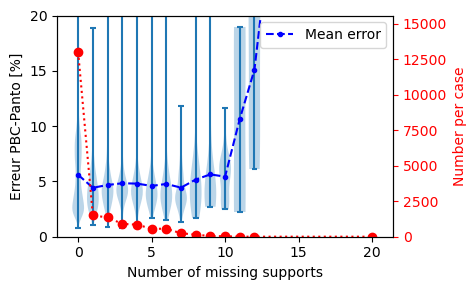

In [18]:

def err_per_number_of_ms(data: dict[Test], eoi:tuple=(0,3), step:float=0.9, width:float=0.1) -> None:
    x_scatter, y_scatter = [], []
    for _, test in data.items():
        err = test.get_error(eoi)
        number_missing_support = sum([len(i) for i in test.skipped_cyl])
        x_scatter.append(number_missing_support)
        y_scatter.append(err)

    X_sorted, Y_sorted = (list(t) for t in zip(*sorted(zip(x_scatter, y_scatter))))
    old = X_sorted[0]
    X_bulk, Y_bulk, number_per_x= [old], [[]], []
    counter=0
    for x, y in zip(X_sorted, Y_sorted):
        if x<old+step:
            Y_bulk[-1].append(y)
            counter+=1
            continue
        number_per_x.append(counter)
        X_bulk.append(x)
        Y_bulk.append([y])
        old = x
        counter=0
    number_per_x.append(counter)
    y_mean = []
    for y in Y_bulk:
        y_mean.append(np.mean(np.array(y)))
    y_mean = np.array(y_mean)

    plt.violinplot(Y_bulk, X_bulk,widths=width,
                   showmeans=False, showmedians=False, showextrema=True)
    plt.plot(X_bulk, y_mean, '.b--', label='Mean error')
    plt.xlabel(f'Number of missing supports')
    plt.ylim((-0,20))
    plt.ylabel('Erreur PBC-Panto [%]')
    plt.legend()
    ax2=plt.twinx()
    ax2.set_ylim(bottom=0, top=1.2*np.max(number_per_x))
    ax2.plot(X_bulk, number_per_x, 'ro:')
    ax2.set_ylabel('Number per case', color='r')
    ax2.tick_params(axis='y', colors='red')


# to_plot=['data', 'data_scale_7','data_scale_8', 'data_scale_9', 'data_scale_10', 
#          'data_scale_11', 'data_scale_12', 'data_scale_13']
to_plot=['data']

plt.figure(figsize=(5,3))
err_per_number_of_ms(data_bulk, width=0.8)
plt.tight_layout()
plt.savefig('images/MS_full.pdf')

Lecture des données réalisée en 1.33622s
midnightblue


<ipython-input-19-431f1be19695>:50: UserWarning: Attempted to set non-positive bottom ylim on a log-scaled axis.
Invalid limit will be ignored.
  plt.ylim(bottom=0.0)


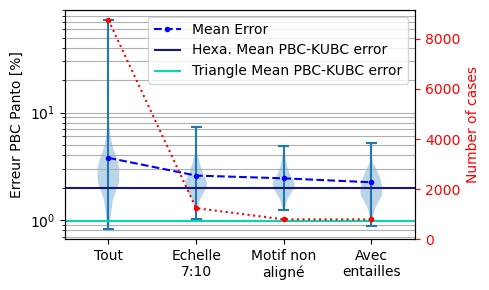

WORSE
honey_7_9_5_0
4.879605942531378


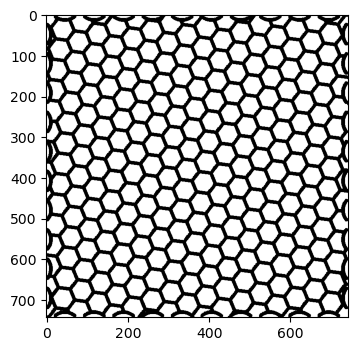

honey_7_3_4_2
4.517448541268526


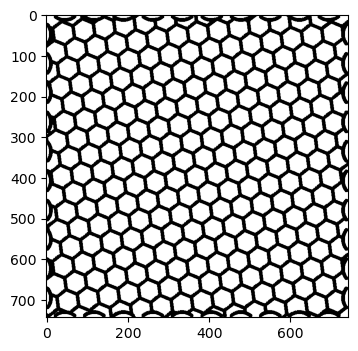

BEST
tria_7_8_9_0
1.239523167591736


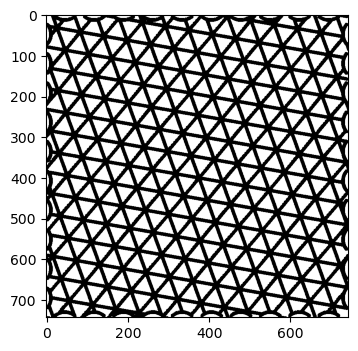

tria_7_4_9_0
1.2452015847090254


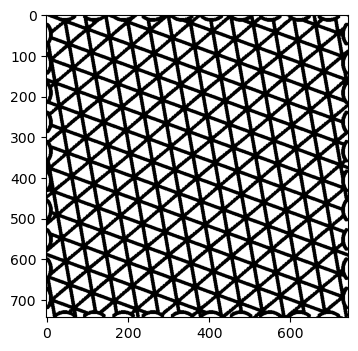

In [19]:

# ~ Elimination des cas problématiques

data_raw = get_bulk_data(read_data_from_campaigns(['campagne_honey','campagne_trian']))

data_list = [[], [], [], []]
last_tests_dict={}
eoi = (0, 3)
for test_id, test in data_raw.items():
    # * list of conditions
    stage = 0
    data_list[stage].append(test.get_error(eoi))

    if test.test_id.split('_')[1] not in ['7']:  # * Si l'angle est de 0 ou 15°
        continue
    stage += 1
    data_list[stage].append(test.get_error(eoi))

    
    if test.test_id.split('_')[0]=='carre':
        if test.test_id.split('_')[2] in ['0','1','15','16']:
            continue
    else:
        if test.test_id.split('_')[2] in ['0','1','6','11','12']:
            continue
    stage += 1
    data_list[stage].append(test.get_error(eoi))

    t_cc_name=test_id.split('_')
    t_cc_name[0]+='CC'
    t_cc=data_CC_bulk['_'.join(t_cc_name)]
    stage += 1
    data_list[stage].append(t_cc.get_error(eoi))

    last_tests_dict |= {test_id:test}


plt.figure(figsize=(5,3))
plt.yscale('log')
plt.violinplot(data_list, range(len(data_list)), widths=0.25,
               showmeans=False, showmedians=False, showextrema=True)


plt.plot(range(len(data_list)), [np.mean(np.array(i)) for i in data_list], 'b.--', label='Mean Error')
plt.hlines(mean_err_per_geo_th[0][0], -10,10,colors=colors[0], linestyles='-',label='Hexa. Mean PBC-KUBC error')
plt.hlines(mean_err_per_geo_th[0][2], -10,10,colors=colors[2], linestyles='-',label='Triangle Mean PBC-KUBC error')
print(colors[0])


plt.xticks(range(len(data_list)), ['Tout', 'Echelle\n7:10', 'Motif non\naligné', 'Avec\nentailles'])
plt.ylim(bottom=0.0)
plt.ylabel('Erreur PBC Panto [%]')


plt.grid(axis='y', which="both", ls="-")
plt.legend()
plt.xlim((-0.5,3.5))
plt.twinx()
plt.plot(range(len(data_list)), [len(i) for i in data_list], 'r.:')
plt.ylabel('Number of cases', color='r')
plt.tick_params(axis='y', colors='red')
plt.ylim(bottom=0.0)

plt.tight_layout()
plt.savefig('images/MS_full_selection.pdf')
plt.show()

print('WORSE')
wb_tests=get_worse_test(last_tests_dict,number=2)
for t in wb_tests:
    print(t.test_id)
    print(t.get_error((0,3)))
    t.show_geo()

print('BEST')
wb_tests=get_best_test(last_tests_dict,number=2)
for t in wb_tests:
    print(t.test_id)
    print(t.get_error((0,3)))
    t.show_geo()


Lecture des données réalisée en 0.37586s
WORSE
hexac_10_0_3_2
15.707301573795194


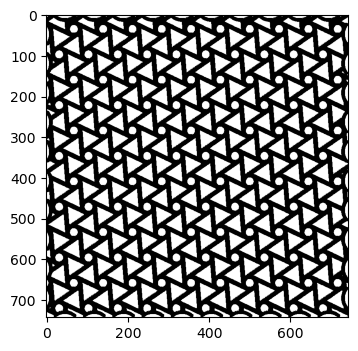

hexac_10_0_2_3
15.6856952743266


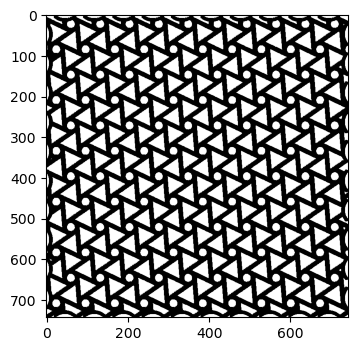

BEST
hexac_13_6_5_0
3.565985663209635


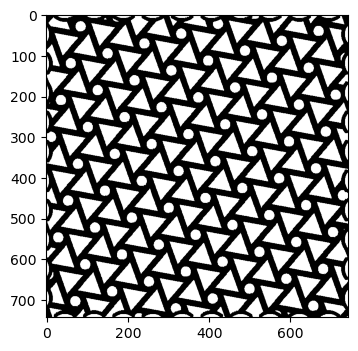

hexac_9_11_1_0
3.66297363788662


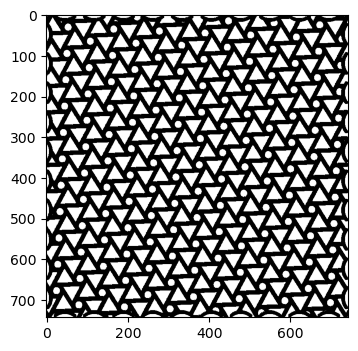

In [20]:
data_raw_hexac = get_bulk_data(read_data_from_campaigns(['campagne_hexac']))
                               
print('WORSE')
wb_tests=get_worse_test(data_raw_hexac,number=2)
for t in wb_tests:
    print(t.test_id)
    print(t.get_error((0,3)))
    t.show_geo()

print('BEST')
wb_tests=get_best_test(data_raw_hexac,number=2)
for t in wb_tests:
    print(t.test_id)
    print(t.get_error((0,3)))
    t.show_geo()